# Data Exploration 

In [2]:

from pathlib import Path
from pandas.plotting import scatter_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
DATA_DIR = Path.cwd() / "Data"
print(f"Using data directory: {DATA_DIR}")
import statistics as st


Using data directory: c:\Users\dinil\OneDrive\Documents\GitHub\Fulfillment-Pulsa\Data


In [3]:
temperature = pd.read_csv(DATA_DIR / "Temperature_Data.csv")
rainfall = pd.read_csv(DATA_DIR / "rainfall_Data.csv")

print("rainfall shape:", rainfall.shape)
print("rainfall shape:", rainfall.shape)
print("rainfall columns:", list(rainfall.columns))
print("rainfall columns:", list(rainfall.columns))


rainfall shape: (254, 8)
rainfall shape: (254, 8)
rainfall columns: ['Product code', 'Bureau of Meteorology station number', 'Year', 'Month', 'Day', 'Rainfall amount (millimetres)', 'Period over which rainfall was measured (days)', 'Quality']
rainfall columns: ['Product code', 'Bureau of Meteorology station number', 'Year', 'Month', 'Day', 'Rainfall amount (millimetres)', 'Period over which rainfall was measured (days)', 'Quality']


In [91]:
temperature.head()

,Product code,Bureau of Meteorology station number,Year,Month,Day,Maximum temperature (Degree C),Days of accumulation of maximum temperature,Quality
0,IDCJAC0010,86338,2013,1,1,NaN,NaN,NaN
1,IDCJAC0010,86338,2013,1,2,NaN,NaN,NaN
2,IDCJAC0010,86338,2013,1,3,NaN,NaN,NaN
3,IDCJAC0010,86338,2013,1,4,NaN,NaN,NaN
4,IDCJAC0010,86338,2013,1,5,NaN,NaN,NaN


In [92]:
len(temperature.iloc[:])

5001

# Temperature dataset exploration

In [ ]:
print("Missing values by column:")
print(temperature.isna().sum())
print("Total missing values:", temperature.isna().sum().sum())

Product code                                     0
Bureau of Meteorology station number             0
Year                                             0
Month                                            0
Day                                              0
Maximum temperature (Degree C)                 155
Days of accumulation of maximum temperature    155
Quality                                        156
dtype: int64
<bound method DataFrame.sum of       Product code  Bureau of Meteorology station number   Year  Month    Day  \
0            False                                 False  False  False  False   
1            False                                 False  False  False  False   
2            False                                 False  False  False  False   
3            False                                 False  False  False  False   
4            False                                 False  False  False  False   
...            ...                                   ...    ..

In [ ]:
temperature.isna().sum()

None
Product code                                   0
Bureau of Meteorology station number           0
Year                                           0
Month                                          0
Day                                            0
Maximum temperature (Degree C)                 0
Days of accumulation of maximum temperature    0
Quality                                        0
dtype: int64


In [80]:
temperature['Maximum temperature (Degree C)'].describe()

count    4846.000000
mean       20.350929
std         6.020962
min         9.000000
25%        15.800000
50%        19.100000
75%        23.600000
max        43.500000
Name: Maximum temperature (Degree C), dtype: float64

In [ ]:
temperature["date"] = pd.to_datetime(temperature[["Year", "Month", "Day"]])


In [ ]:
temperature.duplicated().sum()

np.int64(0)

In [ ]:
temp_column = "Maximum temperature (Degree C)"
condition_one = temperature[temp_column] > 30
condition_two = temperature["date"].dt.year >= 2020

temperature.loc[condition_one & condition_two, ["date", temp_column]]

,date,Maximum temperature (Degree C)
2558,2020-01-03,36.6
2564,2020-01-09,31.9
2565,2020-01-10,32.9
2568,2020-01-13,32.2
2569,2020-01-14,33.8
...,...,...
4798,2026-02-20,30.8
4805,2026-02-27,31.0
4806,2026-02-28,30.5
4807,2026-03-01,30.7


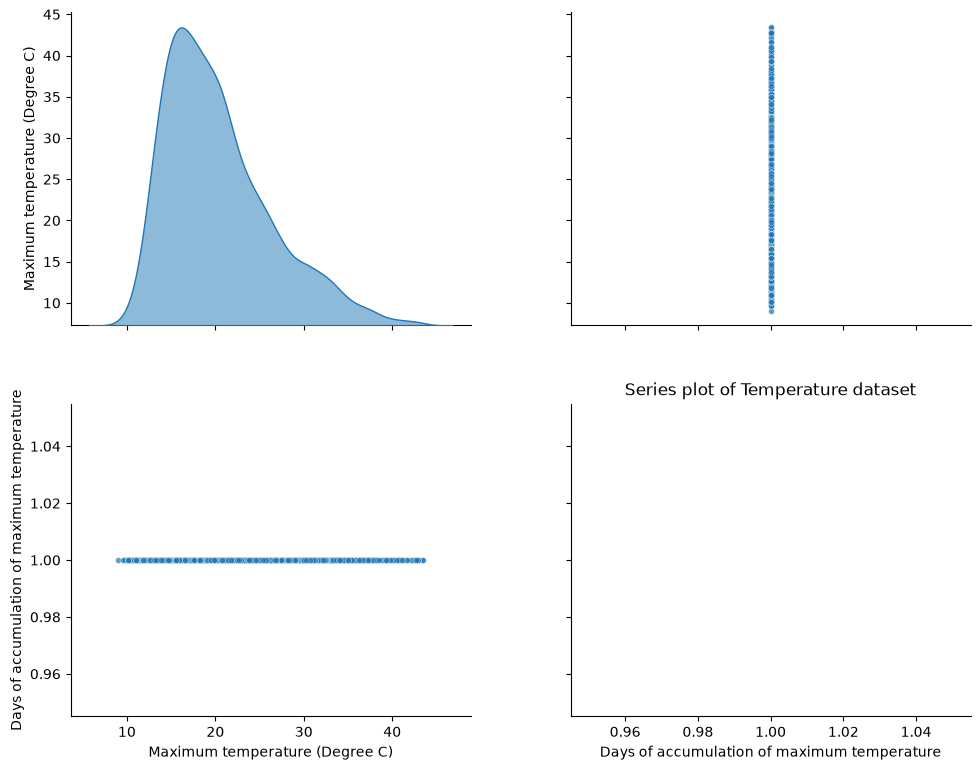

In [83]:
temp_vars = [
    "Maximum temperature (Degree C)",
    "Days of accumulation of maximum temperature",
]

pairplot_df = temperature[temp_vars].dropna()

g = sns.pairplot(
    pairplot_df,
    diag_kind="kde",
    height=2.4,
    aspect=1.1,
    plot_kws={"s": 18, "alpha": 0.7},
    diag_kws={"fill": True, "alpha": 0.5},
)

g.fig.set_size_inches(10, 8)
g.fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.96,
    wspace=0.25,
    hspace=0.25,
)

plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

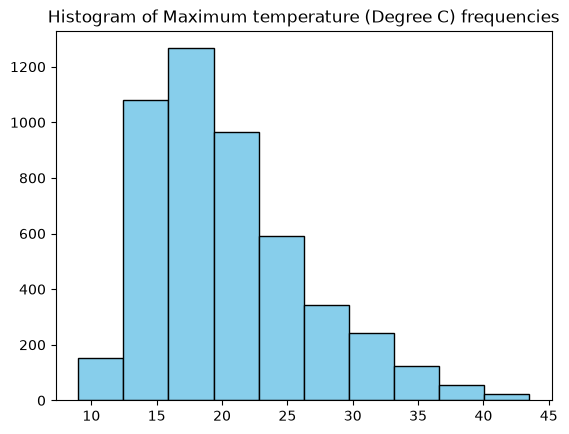

In [82]:
temperature_column = "Maximum temperature (Degree C)"
ax = temperature[temperature_column].hist(
    bins=10,
    color="skyblue",
    edgecolor="black",
)
ax.set_title("Distribution of daily maximum temperatures")
ax.set_xlabel("Maximum temperature (°C)")
ax.set_ylabel("Number of days")
plt.tight_layout()
plt.show()

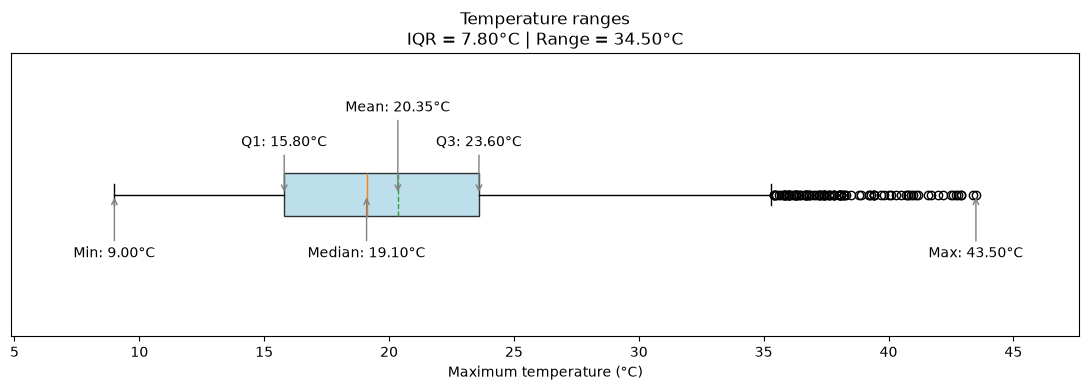

In [ ]:
temps = temperature["Maximum temperature (Degree C)"].dropna()

minimum = temps.min()
maximum = temps.max()
median = temps.median()
mean = temps.mean()
q1 = temps.quantile(0.25)
q3 = temps.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))

ax.boxplot(
    temps,
    showmeans=True,
    orientation="horizontal",
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

labels = [
    ("Min", minimum, -45),
    ("Q1", q1, 35),
    ("Median", median, -45),
    ("Mean", mean, 60),
    ("Q3", q3, 35),
    ("Max", maximum, -45),
]

for label, value, offset in labels:
    ax.annotate(
        f"{label}: {value:.2f}°C",
        xy=(value, 1),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        arrowprops=dict(arrowstyle="->", color="gray")
    )

ax.set_title(
    f"Temperature ranges\n"
    f"IQR = {IQR:.2f}°C | Range = {maximum - minimum:.2f}°C"
)
ax.set_xlabel("Maximum temperature (°C)")
ax.set_yticks([])
ax.margins(x=0.12)

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

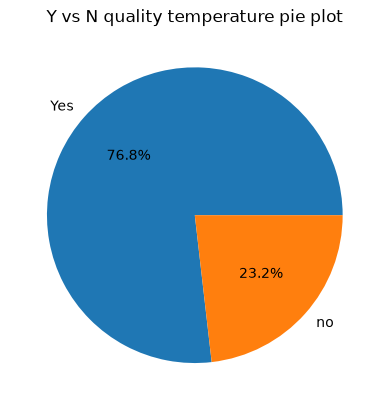

In [ ]:
temperature_quality = temperature["Quality"].fillna("Missing").value_counts()

ax = temperature_quality.plot(kind="bar", figsize=(6, 4), color="tab:blue")
ax.set_xlabel("Temperature quality flag")
ax.set_ylabel("Number of records")
ax.set_title("Temperature records by quality flag")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

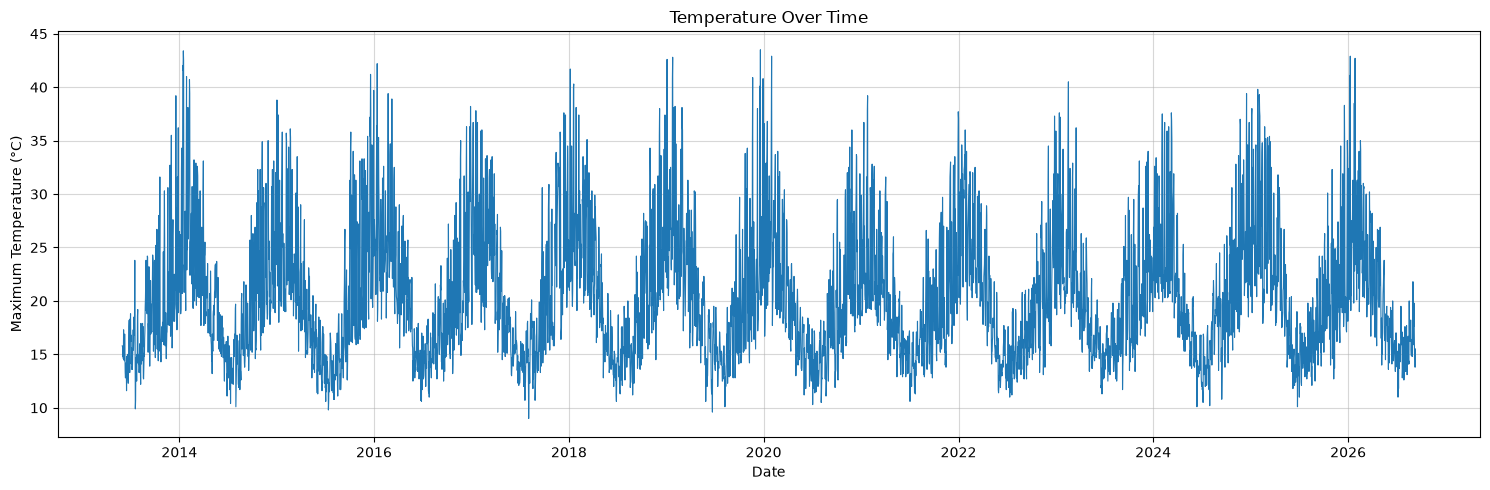

In [ ]:
import matplotlib.pyplot as plt

# Time series plot for maximum temperature

temperature = temperature.copy()
temperature["date"] = pd.to_datetime(temperature["date"])
temperature = temperature.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    temperature["date"],
    temperature["Maximum temperature (Degree C)"],
    linewidth=0.8,
    color="tab:blue",
)
ax.set_xlabel("Date")
ax.set_ylabel("Maximum Temperature (°C)")
ax.set_title("Temperature Over Time")
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
temperature.info()

<class 'pandas.DataFrame'>
RangeIndex: 4845 entries, 0 to 4844
Data columns (total 9 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   Product code                                 4845 non-null   str           
 1   Bureau of Meteorology station number         4845 non-null   int64         
 2   Year                                         4845 non-null   int64         
 3   Month                                        4845 non-null   int64         
 4   Day                                          4845 non-null   int64         
 5   Maximum temperature (Degree C)               4845 non-null   float64       
 6   Days of accumulation of maximum temperature  4845 non-null   float64       
 7   Quality                                      4845 non-null   str           
 8   date                                         4845 non-null   datetime64[us]
dtypes: dateti

# Rainfall data exploration

In [ ]:
rainfall.isnull().sum()

Product code                                        0
Bureau of Meteorology station number                0
Year                                                0
Month                                               0
Day                                                 0
Rainfall amount (millimetres)                       0
Period over which rainfall was measured (days)    152
Quality                                             0
dtype: int64

In [ ]:
rainfall.describe()

,Bureau of Meteorology station number,Year,Month,Day,Rainfall amount (millimetres),Period over which rainfall was measured (days)
count,254.0,254.0,254.000000,254.000000,254.000000,102.0
mean,86232.0,2026.0,4.720472,15.283465,1.461811,1.0
std,0.0,0.0,2.427733,8.864280,3.536137,0.0
min,86232.0,2026.0,1.000000,1.000000,0.000000,1.0
25%,86232.0,2026.0,3.000000,8.000000,0.000000,1.0
50%,86232.0,2026.0,5.000000,15.000000,0.000000,1.0
75%,86232.0,2026.0,7.000000,23.000000,1.000000,1.0
max,86232.0,2026.0,9.000000,31.000000,25.000000,1.0


In [ ]:
rainfall["date"] = pd.to_datetime(rainfall[["Year", "Month", "Day"]])

In [ ]:
rainfall.duplicated().sum()

np.int64(0)

In [ ]:
rain_column = "Rainfall amount (millimetres)"

rainfall.loc[
    rainfall[rain_column].idxmax(),
    ["date", rain_column]
]

date                             2026-08-10 00:00:00
Rainfall amount (millimetres)                   25.0
Name: 221, dtype: object

In [ ]:
rain_column = "Rainfall amount (millimetres)"

rainfall.loc[
    rainfall[rain_column].idxmin(),
    ["date", rain_column]
]

date                             2026-01-01 00:00:00
Rainfall amount (millimetres)                    0.0
Name: 0, dtype: object

In [ ]:
rainy_days = rainfall[
    rainfall["Rainfall amount (millimetres)"] > 0
].copy()

rainy_days

,Product code,Bureau of Meteorology station number,Year,Month,Day,Rainfall amount (millimetres),Period over which rainfall was measured (days),Quality,date
9,IDCJAC0009,86232,2026,1,10,0.3,1.0,Y,2026-01-10
21,IDCJAC0009,86232,2026,1,22,0.6,1.0,Y,2026-01-22
31,IDCJAC0009,86232,2026,2,1,1.7,1.0,N,2026-02-01
39,IDCJAC0009,86232,2026,2,9,1.4,1.0,N,2026-02-09
42,IDCJAC0009,86232,2026,2,12,11.2,1.0,N,2026-02-12
...,...,...,...,...,...,...,...,...,...
240,IDCJAC0009,86232,2026,8,29,1.7,1.0,N,2026-08-29
246,IDCJAC0009,86232,2026,9,4,2.8,1.0,N,2026-09-04
247,IDCJAC0009,86232,2026,9,5,7.6,1.0,N,2026-09-05
248,IDCJAC0009,86232,2026,9,6,0.8,1.0,N,2026-09-06


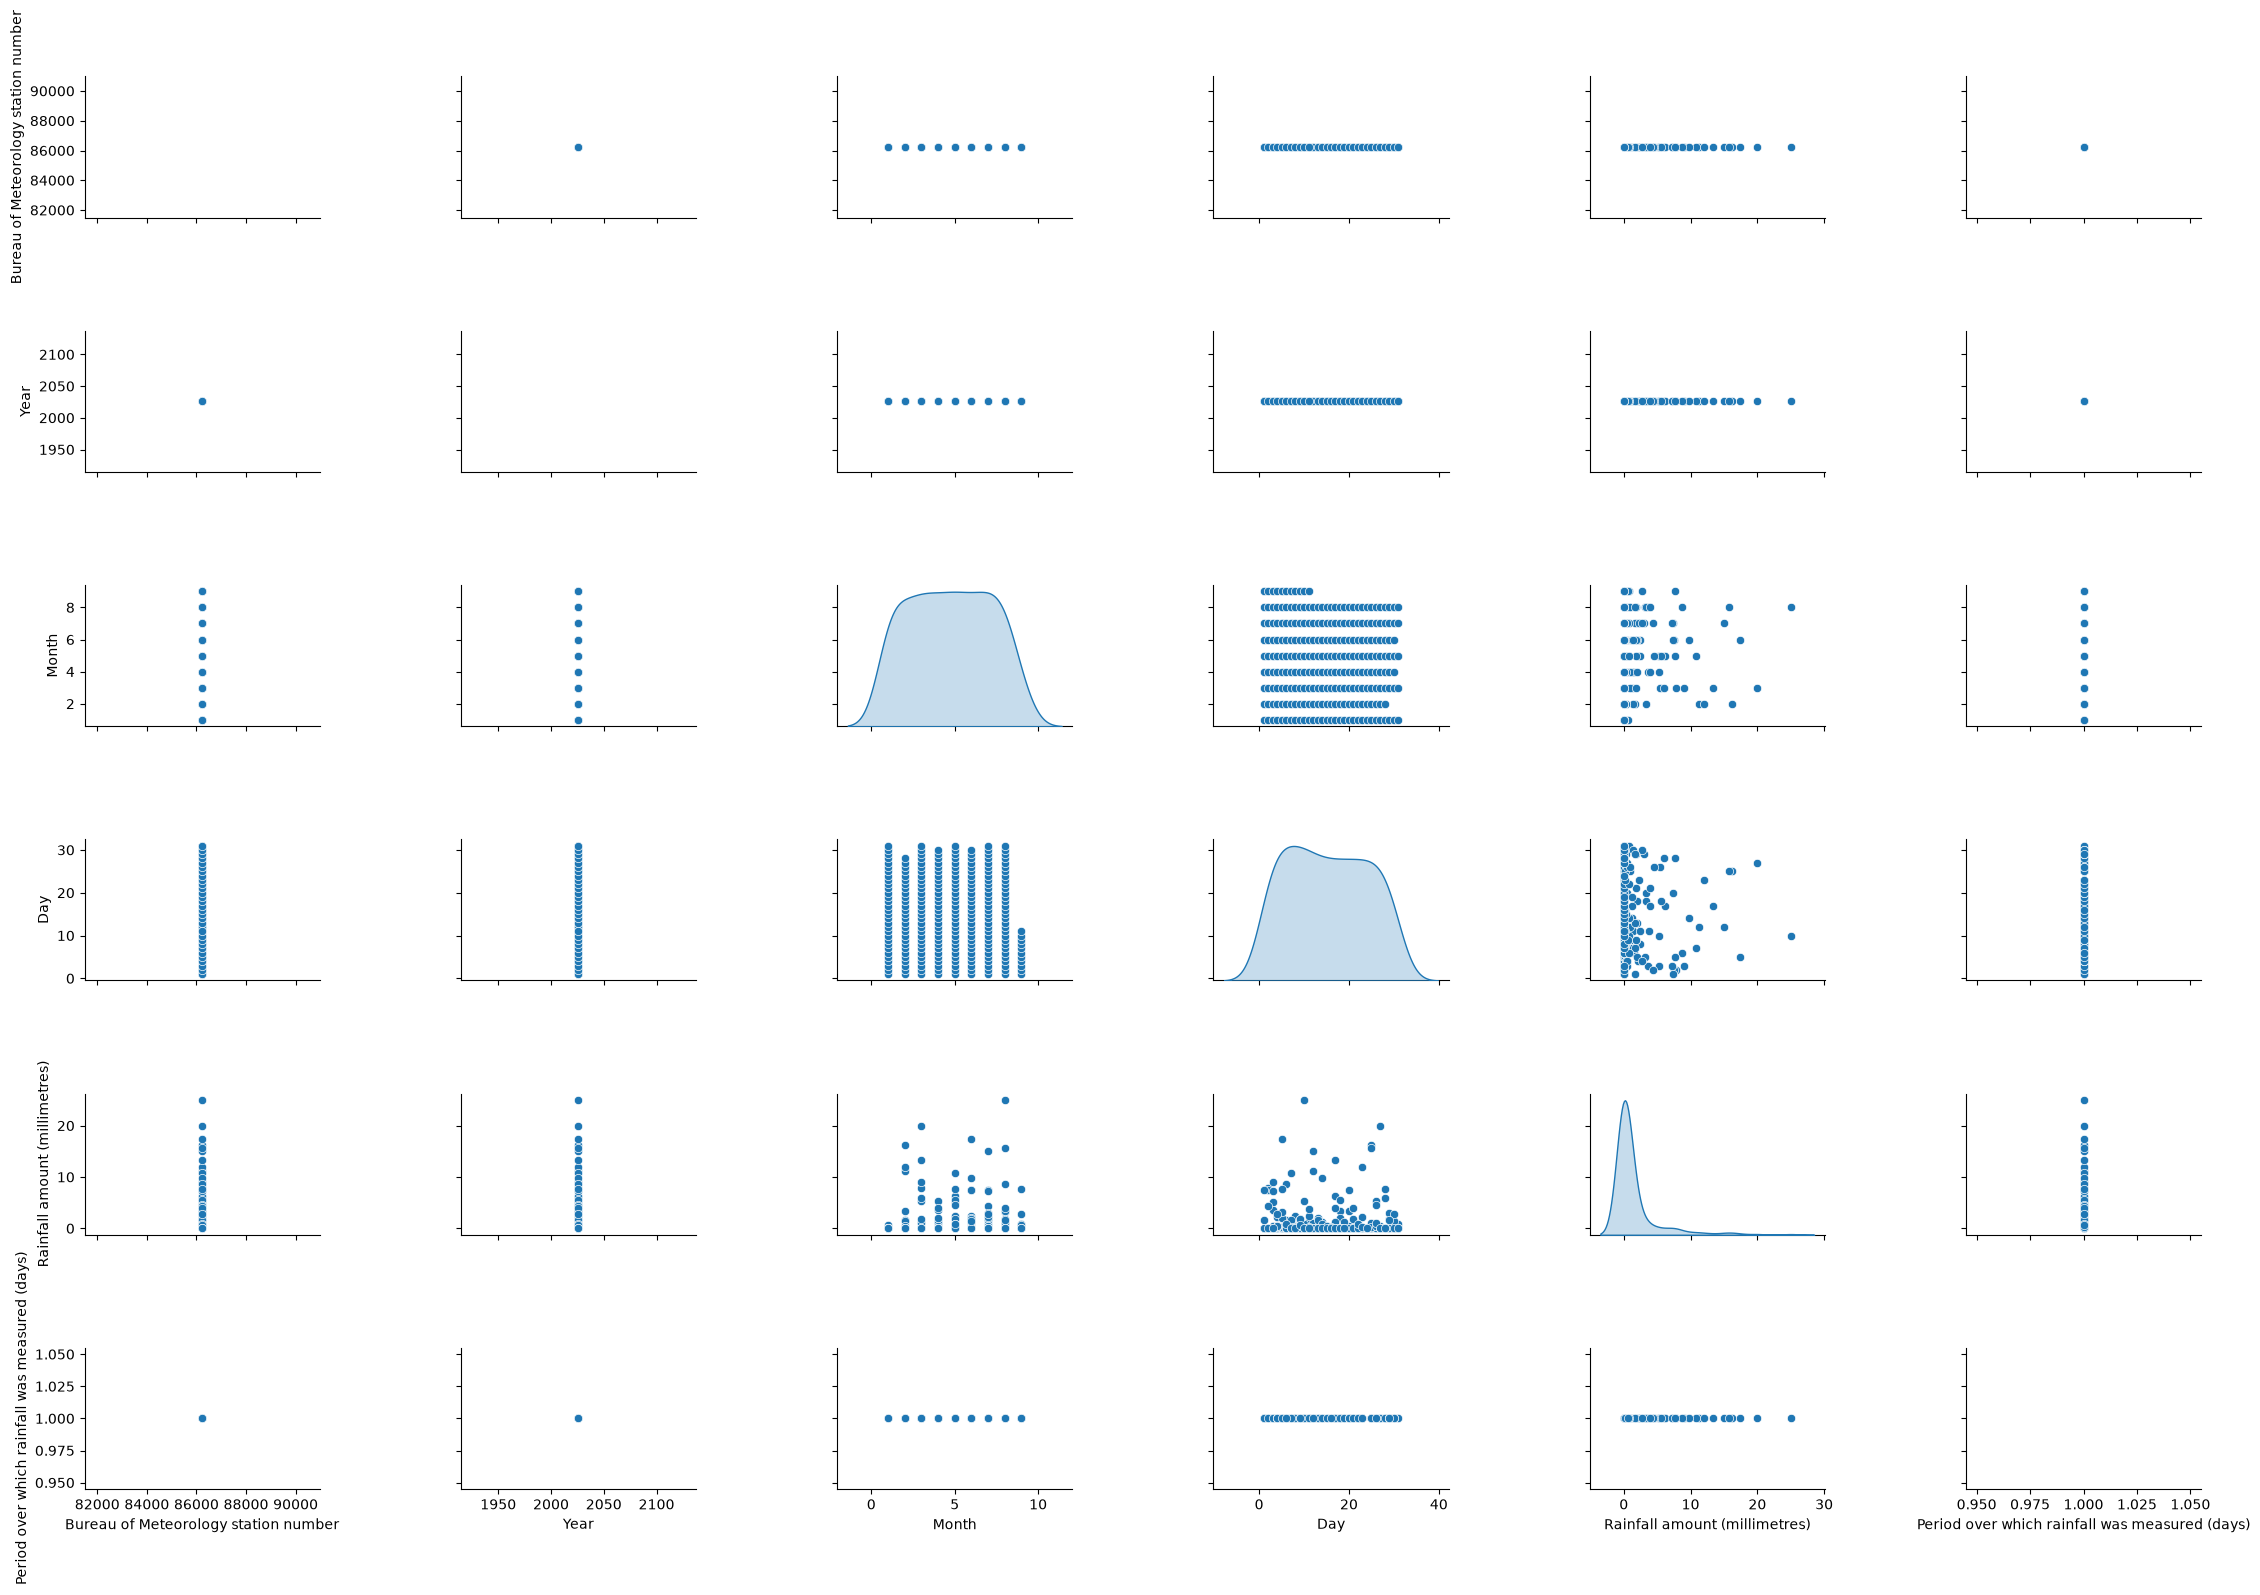

In [ ]:
# 2. Generate the pairplot
# 'hue' color-codes the data points based on a categorical column
plot = sns.pairplot(rainfall,  diag_kind='kde', height=2.5, aspect=1.5)
plot.figure.subplots_adjust(wspace=0.6, hspace=0.8)



C:\Users\dinil\AppData\Local\Temp\ipykernel_32100\771989217.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


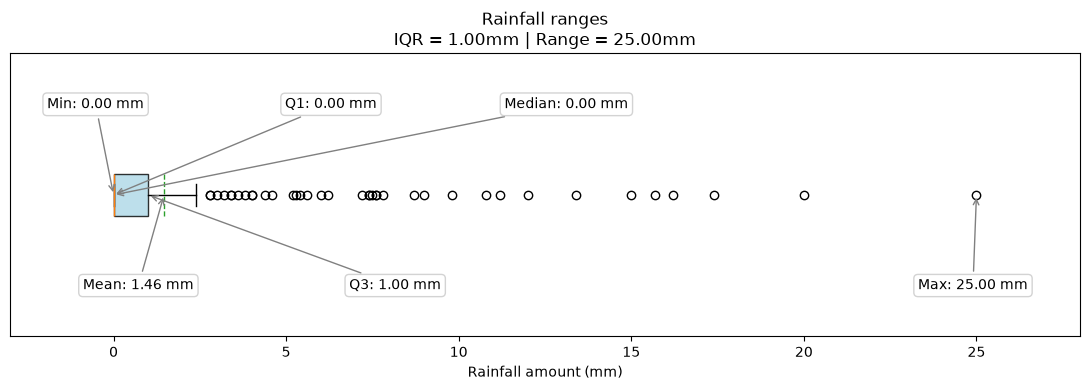

In [ ]:
rain = rainfall["Rainfall amount (millimetres)"].dropna()

minimum = rain.min()
maximum = rain.max()
median = rain.median()
mean = rain.mean()
q1 = rain.quantile(0.25)
q3 = rain.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))

ax.boxplot(
    rain,
    showmeans=True,
    vert=False,
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

# Space labels across the axes even when several statistics are near zero.
labels = [
    ("Min", minimum, (0.08, 0.82)),
    ("Q1", q1, (0.30, 0.82)),
    ("Median", median, (0.52, 0.82)),
    ("Mean", mean, (0.12, 0.18)),
    ("Q3", q3, (0.36, 0.18)),
    ("Max", maximum, (0.90, 0.18)),
]

for label, value, position in labels:
    ax.annotate(
        f"{label}: {value:.2f} mm",
        xy=(value, 1),
        xytext=position,
        textcoords="axes fraction",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray"),
        arrowprops=dict(arrowstyle="->", color="gray"),
    )

ax.set_title(
    f"Rainfall ranges\n"
    f"IQR = {IQR:.2f}mm | Range = {maximum - minimum:.2f}mm"
)
ax.set_xlabel("Rainfall amount (mm)")
ax.set_yticks([])
ax.margins(x=0.12)

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

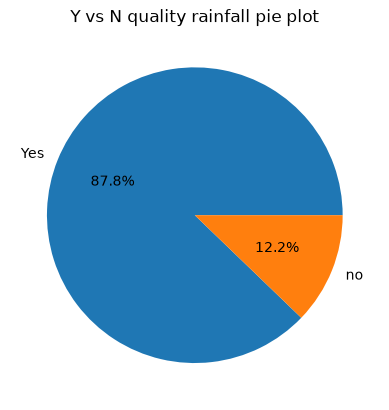

In [ ]:
rainfall_quality = rainfall["Quality"].fillna("Missing").value_counts()

ax = rainfall_quality.plot(kind="bar", figsize=(6, 4), color="tab:blue")
ax.set_xlabel("Rainfall quality flag")
ax.set_ylabel("Number of records")
ax.set_title("Rainfall records by quality flag")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

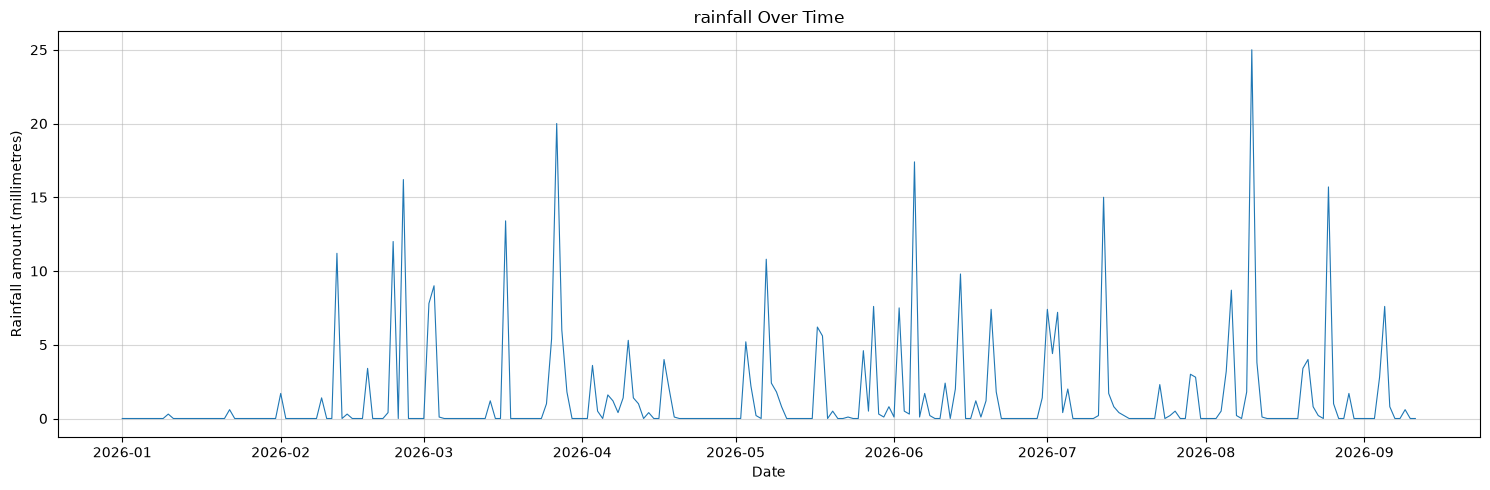

In [ ]:
import matplotlib.pyplot as plt

# Time series plot for maximum temperature

rainfall = rainfall.copy()
rainfall["date"] = pd.to_datetime(rainfall["date"])
rainfall = rainfall.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    rainfall["date"],
    rainfall["Rainfall amount (millimetres)"],
    linewidth=0.8,
    color="tab:blue",
)
ax.set_xlabel("Date")
ax.set_ylabel("Rainfall amount (millimetres)")
ax.set_title("rainfall Over Time")
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# Order data exploration

In [4]:

order = pd.read_csv("Data\\fictitious_orders_melbourne.csv")
display(order)

,order_id,order_timestamp,delivery_zone,item_count,promised_window,fulfilment_stage,basket_category,simulated_delay_flag,is_synthetic
0,ORD-20260101-001,2026-01-01 08:10,Melbourne CBD,3,08:00-10:00,packed,groceries,False,True
1,ORD-20260101-002,2026-01-01 09:45,Inner North,5,09:00-11:00,picked,household,False,True
2,ORD-20260101-003,2026-01-01 12:15,South East Melbourne,2,12:00-14:00,packed,essentials,False,True
3,ORD-20260101-004,2026-01-01 18:20,Western Suburbs,4,18:00-20:00,packed,groceries,False,True
4,ORD-20260101-005,2026-01-01 20:05,Eastern Suburbs,6,19:30-21:30,dispatched,meal-kit,False,True
5,ORD-20260102-006,2026-01-02 07:55,Northern Suburbs,2,08:00-09:30,picked,essentials,False,True
6,ORD-20260102-007,2026-01-02 10:30,Melbourne CBD,7,10:00-12:00,packed,office-supplies,False,True
7,ORD-20260102-008,2026-01-02 12:40,South East Melbourne,3,12:00-14:00,dispatched,groceries,True,True
8,ORD-20260102-009,2026-01-02 15:10,Inner North,4,15:00-17:00,packed,health,False,True
9,ORD-20260102-010,2026-01-02 19:50,Western Suburbs,8,18:30-21:00,dispatched,bulk-order,False,True


In [5]:
order["order_timestamp"] = pd.to_datetime(order["order_timestamp"])

In [ ]:
order["item_count"].describe()

count    30.000000
mean      4.433333
std       2.028815
min       2.000000
25%       3.000000
50%       4.000000
75%       6.000000
max       9.000000
Name: item_count, dtype: float64

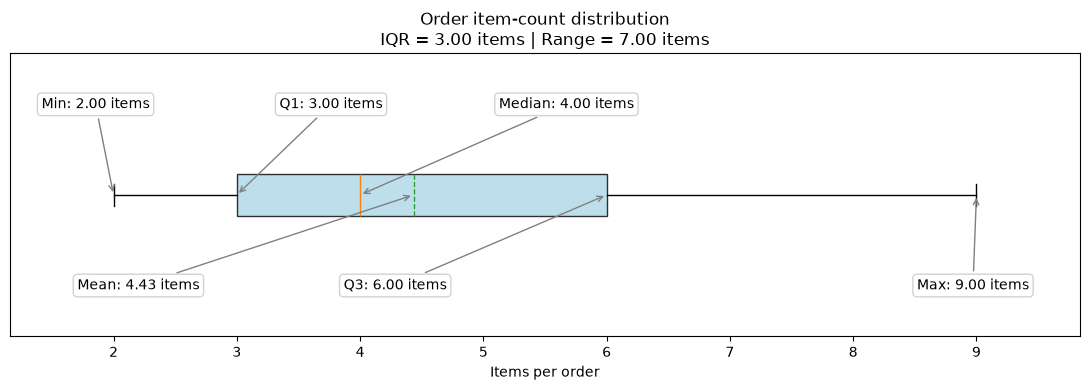

In [94]:
item_counts = order["item_count"].dropna()

minimum = item_counts.min()
maximum = item_counts.max()
median = item_counts.median()
mean = item_counts.mean()
q1 = item_counts.quantile(0.25)
q3 = item_counts.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(
    item_counts,
    showmeans=True,
    orientation="horizontal",
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

labels = [
    ("Min", minimum, (0.08, 0.82)),
    ("Q1", q1, (0.30, 0.82)),
    ("Median", median, (0.52, 0.82)),
    ("Mean", mean, (0.12, 0.18)),
    ("Q3", q3, (0.36, 0.18)),
    ("Max", maximum, (0.90, 0.18)),
]

for label, value, position in labels:
    ax.annotate(
        f"{label}: {value:.2f} items",
        xy=(value, 1),
        xytext=position,
        textcoords="axes fraction",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray"),
        arrowprops=dict(arrowstyle="->", color="gray"),
    )

ax.set_title(
    f"Order item-count distribution\n"
    f"IQR = {IQR:.2f} items | Range = {maximum - minimum:.2f} items"
)
ax.set_xlabel("Items per order")
ax.set_yticks([])
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

In [6]:
item_counts = order["item_count"].dropna()
q1 = item_counts.quantile(0.25)
q3 = item_counts.quantile(0.75)
IQR = q3 - q1
lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = order.loc[
    (order["item_count"] < lower_bound) | (order["item_count"] > upper_bound),
    ["order_id", "item_count"],
]

print(f"Outlier bounds: {lower_bound:.2f} to {upper_bound:.2f} items")
display(outliers)

Outlier bounds: -1.50 to 10.50 items


,order_id,item_count


In [ ]:
order.shape

(30, 9)

In [ ]:
order.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   order_id              30 non-null     str           
 1   order_timestamp       30 non-null     datetime64[us]
 2   delivery_zone         30 non-null     str           
 3   item_count            30 non-null     int64         
 4   promised_window       30 non-null     str           
 5   fulfilment_stage      30 non-null     str           
 6   basket_category       30 non-null     str           
 7   simulated_delay_flag  30 non-null     bool          
 8   is_synthetic          30 non-null     bool          
dtypes: bool(2), datetime64[us](1), int64(1), str(5)
memory usage: 1.8 KB


In [ ]:
order.isna().sum()

order_id                0
order_timestamp         0
delivery_zone           0
item_count              0
promised_window         0
fulfilment_stage        0
basket_category         0
simulated_delay_flag    0
is_synthetic            0
dtype: int64

In [ ]:
# l = [1, 2, 3, 4, 5, 6]
# a = 0
# for p in l:
#     a = a + 1
#     print(order
print(order.isna().sum().sum())
print(order.isnull().sum().sum())

0
0


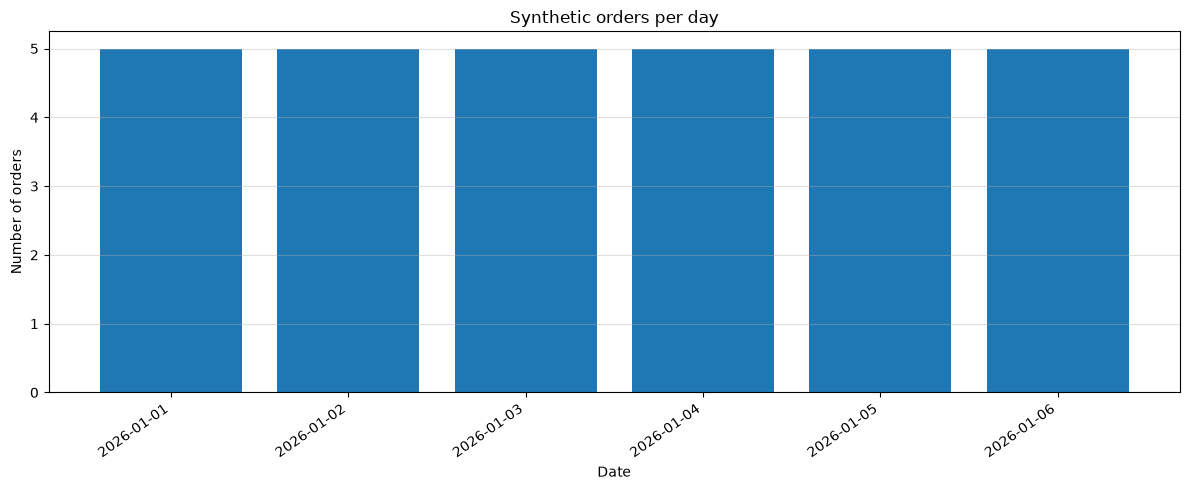

In [95]:
daily_order_counts = order.set_index("order_timestamp").resample("D").size()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(daily_order_counts.index, daily_order_counts.values, color="tab:blue")
ax.set_xlabel("Date")
ax.set_ylabel("Number of orders")
ax.set_title("Synthetic orders per day")
ax.grid(axis="y", alpha=0.4)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

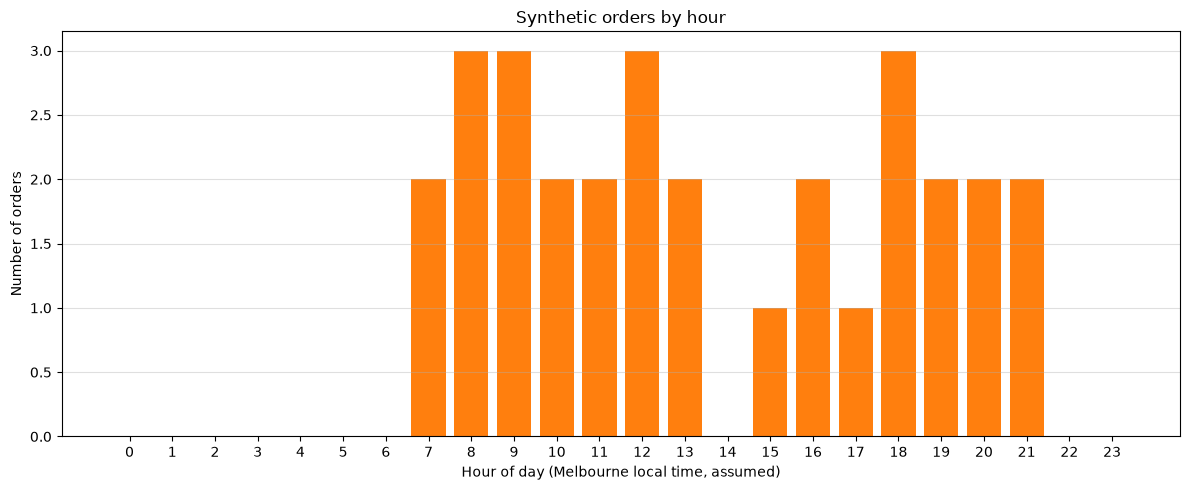

In [96]:
orders_by_hour = order["order_timestamp"].dt.hour.value_counts().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(orders_by_hour.index, orders_by_hour.values, color="tab:orange")
ax.set_xlabel("Hour of day (Melbourne local time, assumed)")
ax.set_ylabel("Number of orders")
ax.set_title("Synthetic orders by hour")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

delivery_zone
Melbourne CBD           31
South East Melbourne    24
Western Suburbs         23
Eastern Suburbs         23
Inner North             18
Northern Suburbs        14
Name: total_items, dtype: int64

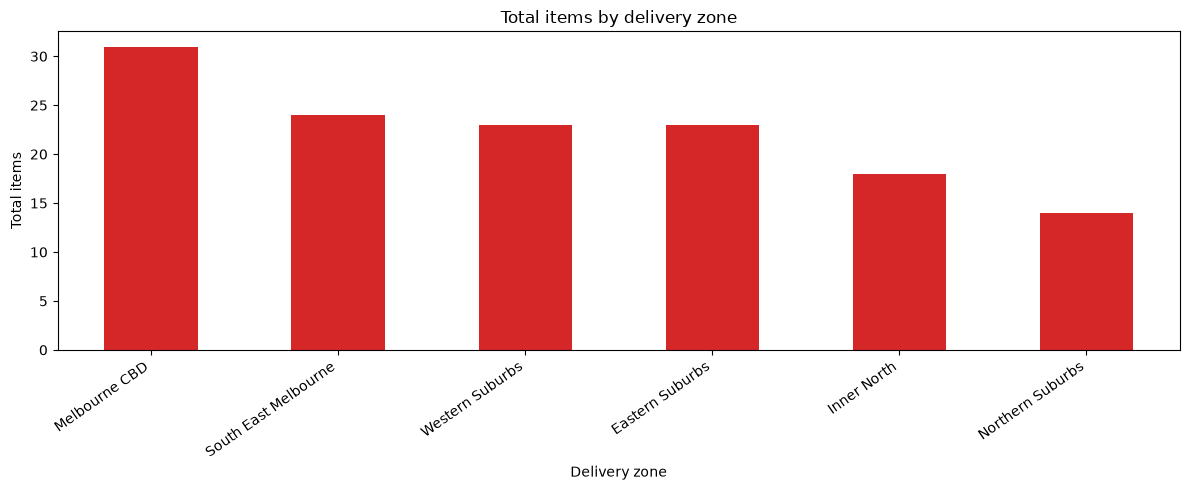

In [7]:
items_by_zone = order.groupby("delivery_zone")["item_count"].sum().sort_values(ascending=False)

display(items_by_zone.rename("total_items"))
ax = items_by_zone.plot(kind="bar", figsize=(12, 5), color="tab:red")
ax.set_xlabel("Delivery zone")
ax.set_ylabel("Total items")
ax.set_title("Total items by delivery zone")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

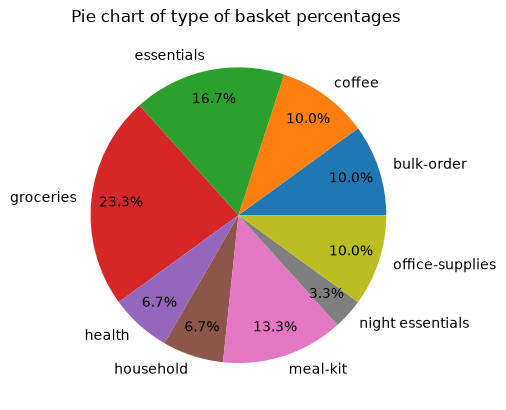

In [ ]:
basket_counts = order["basket_category"].value_counts()

ax = basket_counts.plot(kind="bar", figsize=(10, 5), color="tab:green")
ax.set_xlabel("Basket category")
ax.set_ylabel("Number of orders")
ax.set_title("Orders by basket category")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Pie chart of fufilment category')

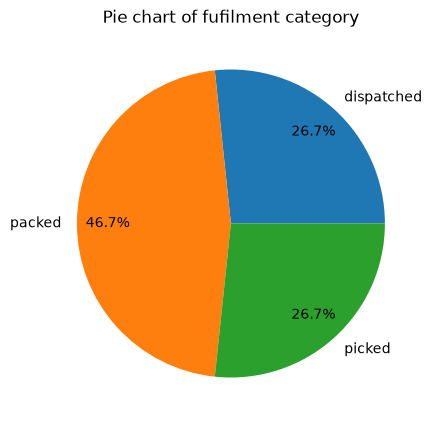

In [ ]:
fulfilment_counts = order["fulfilment_stage"].value_counts()

ax = fulfilment_counts.plot(kind="bar", figsize=(7, 5), color="tab:blue")
ax.set_xlabel("Fulfilment stage")
ax.set_ylabel("Number of orders")
ax.set_title("Orders by fulfilment stage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Pie chart of simulated delay flag')

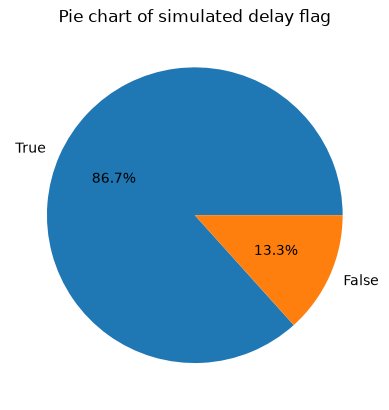

In [ ]:
delay_counts = order["simulated_delay_flag"].value_counts()

ax = delay_counts.plot(kind="bar", figsize=(6, 4), color="tab:orange")
ax.set_xlabel("Simulated delay flag")
ax.set_ylabel("Number of orders")
ax.set_title("Orders by simulated delay flag")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
order

,order_id,order_timestamp,delivery_zone,item_count,promised_window,fulfilment_stage,basket_category,simulated_delay_flag,is_synthetic
0,ORD-20260101-001,2026-01-01 08:10:00,Melbourne CBD,3,08:00-10:00,packed,groceries,False,True
1,ORD-20260101-002,2026-01-01 09:45:00,Inner North,5,09:00-11:00,picked,household,False,True
2,ORD-20260101-003,2026-01-01 12:15:00,South East Melbourne,2,12:00-14:00,packed,essentials,False,True
3,ORD-20260101-004,2026-01-01 18:20:00,Western Suburbs,4,18:00-20:00,packed,groceries,False,True
4,ORD-20260101-005,2026-01-01 20:05:00,Eastern Suburbs,6,19:30-21:30,dispatched,meal-kit,False,True
5,ORD-20260102-006,2026-01-02 07:55:00,Northern Suburbs,2,08:00-09:30,picked,essentials,False,True
6,ORD-20260102-007,2026-01-02 10:30:00,Melbourne CBD,7,10:00-12:00,packed,office-supplies,False,True
7,ORD-20260102-008,2026-01-02 12:40:00,South East Melbourne,3,12:00-14:00,dispatched,groceries,True,True
8,ORD-20260102-009,2026-01-02 15:10:00,Inner North,4,15:00-17:00,packed,health,False,True
9,ORD-20260102-010,2026-01-02 19:50:00,Western Suburbs,8,18:30-21:00,dispatched,bulk-order,False,True


Text(0.5, 1.0, 'Bar chart most number of times for each delivery location')

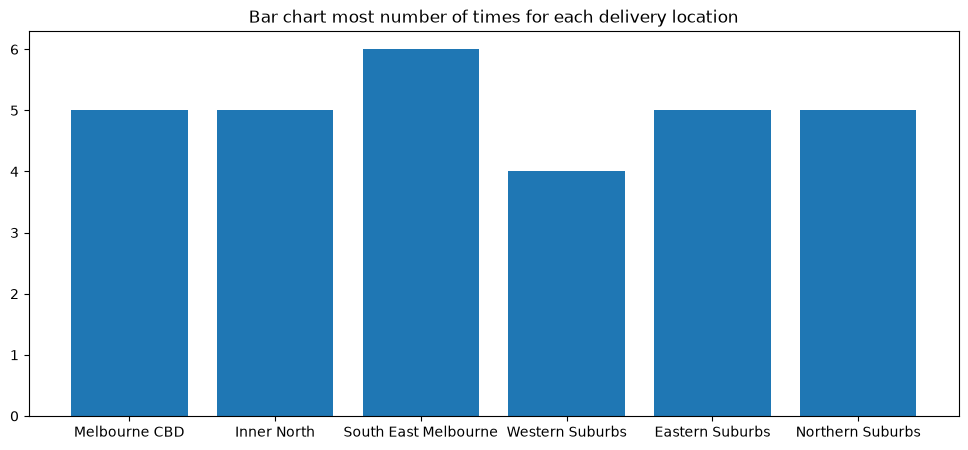

In [ ]:
order_counts_by_zone = order["delivery_zone"].value_counts().sort_values(ascending=False)

ax = order_counts_by_zone.plot(kind="bar", figsize=(10, 5), color="tab:blue")
ax.set_xlabel("Delivery zone")
ax.set_ylabel("Number of orders")
ax.set_title("Number of orders by delivery zone")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Bar chart of delivery zones and number items for each location')

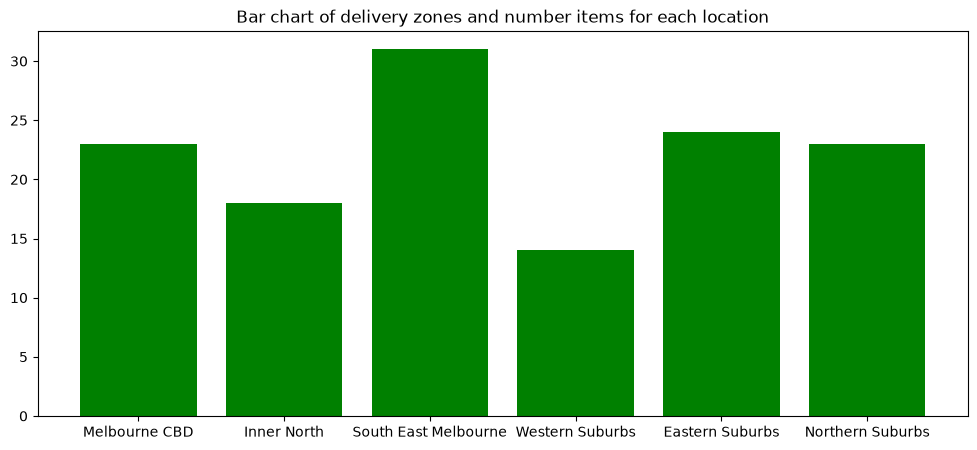